# EOG / EMG data exploration (EDA)

Look at a recording **before** building anything on it. This notebook only explores the data: no detector, no model. The detection is in `EOG_Detection.ipynb`.

It works for any recording with one or more signal channels and (optionally) time marks such as "driver pressed the drowsy button". **To explore another dataset, change only the settings cell and `load_recording` in section 1**; every later cell reads the data through those.

Contents: 1 settings and loading, 2 what is in the files, 3 signal quality, 4 the raw signal, 5 the two eye channels, 6 frequency content, 7 how different people are, 8 slow drift, 9 the marks, 10 insights.

## 1. Settings and loading

In [1]:
import os, urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyedflib
from scipy import signal

# ---- The settings cell: the only thing that depends on the dataset ----
DATASET = {
    "name": "DD-Database (Zenodo 8284057, CC0)",
    "folder": "data/dd_database",
    "url": "https://zenodo.org/api/records/8284057/files/{}/content",
    "recordings": ["01M_1", "02F_1", "03F_1", "04M_1", "05M_1", "06M_1", "07F_1"],   # trial 1 of subjects 1-7
    "fs": 128,                                      # sampling rate (Hz)
    "eye_channels": ("LOC-Ref", "ROC-Ref"),         # electrodes at the outer corners of the eyes; their difference is the eye signal
    "mains_hz": 50,                                 # power-line frequency where it was recorded (50 or 60)
}
FS = DATASET["fs"]

**Dataset: DD-Database** (Drivers Drowsiness Database, Universidad Nacional de San Juan, [Zenodo](https://zenodo.org/records/8284057), CC0). 10 volunteers drove a **night-time driving simulator** for 2 hours (twice), partly sleep-deprived, and pressed a button whenever they **felt drowsy**. Recorded: 2 EOG channels (LOC, ROC), 4 EEG, 1 ECG, 128 Hz, raw. Only trial 1 of subjects 1-7 is used (7 files, 91 MB); subjects 8-10 pressed the button only 2-8 times in total.

In [2]:
def download():
    os.makedirs(DATASET["folder"], exist_ok=True)
    for name in DATASET["recordings"]:
        for suffix in ("", "_annotations"):
            path = f"{DATASET['folder']}/{name}{suffix}.edf"
            if not os.path.exists(path):
                print("downloading", path)
                urllib.request.urlretrieve(DATASET["url"].format(f"{name}{suffix}.edf"), path)


def load_recording(name):
    """One recording -> {"signals": {channel name: microvolts}, "marks": times (s) of the driver's 'I feel drowsy' button presses}.
    For another dataset, rewrite this function (and `download`); nothing else in the notebook changes."""
    r = pyedflib.EdfReader(f"{DATASET['folder']}/{name}.edf")
    signals = {label: r.readSignal(i) for i, label in enumerate(r.getSignalLabels())}
    r.close()
    a = pyedflib.EdfReader(f"{DATASET['folder']}/{name}_annotations.edf")
    marks = np.array(a.readAnnotations()[0])
    a.close()
    return {"signals": signals, "marks": marks[(marks > 30) & (marks < 7000)]}   # the marks at about 10 s and 7220 s are start / end markers


def eye_signal(rec):
    """The eye channel: the difference of the two eye electrodes (or the single channel if only one is given)."""
    a, b = DATASET["eye_channels"]
    return rec["signals"][a] - rec["signals"][b] if b else rec["signals"][a]


download()
data = {name: load_recording(name) for name in DATASET["recordings"]}

## 2. What is in the files?

In [3]:
pd.DataFrame({name: {"length (min)": len(eye_signal(rec)) / FS / 60, "channels": len(rec["signals"]),
                     "marks": len(rec["marks"]), "first mark (min)": rec["marks"][0] / 60 if len(rec["marks"]) else np.nan}
              for name, rec in data.items()}).T.round(1)

,length (min),channels,marks,first mark (min)
01M_1,121.8,7.0,23.0,25.2
02F_1,123.0,7.0,34.0,3.8
03F_1,121.8,7.0,81.0,13.2
04M_1,115.5,7.0,35.0,6.6
05M_1,120.8,7.0,23.0,18.4
06M_1,120.2,7.0,33.0,12.9
07F_1,121.5,7.0,88.0,13.0


In [4]:
print("channels:", list(next(iter(data.values()))["signals"]))

channels: ['O1-Ref', 'O2-Ref', 'C3-Ref', 'C4-Ref', 'LOC-Ref', 'ROC-Ref', 'EKG']


## 3. Is the signal usable? (quality per recording)
Four quick checks on the eye signal: **missing values**, **flat stretches** (1 s windows that barely move: electrode off or amplifier stuck), **clipping** (samples sitting at the extreme value: amplifier saturated) and the **correlation of the two eye channels** (a good pair mirrors each other).

In [5]:
def quality(rec):
    x = eye_signal(rec)
    windows = x[:len(x) // FS * FS].reshape(-1, FS)
    a, b = DATASET["eye_channels"]
    return {"missing (%)": 100 * np.isnan(x).mean(),
            "flat seconds (%)": 100 * np.mean(windows.std(axis=1) < 0.1),
            "at min or max (%)": 100 * np.mean((x == x.max()) | (x == x.min())),
            "spread, std (uV)": np.nanstd(x),
            "eye channels correlation": np.corrcoef(rec["signals"][a], rec["signals"][b])[0, 1] if b else np.nan}

quality_table = pd.DataFrame({name: quality(rec) for name, rec in data.items()}).T
quality_table.round(2)

,missing (%),flat seconds (%),at min or max (%),"spread, std (uV)",eye channels correlation
01M_1,0.0,0.03,0.0,61.91,-0.80
02F_1,0.0,0.03,0.0,107.44,-0.70
03F_1,0.0,0.00,0.0,47.72,-0.45
04M_1,0.0,0.03,0.0,47.82,-0.75
05M_1,0.0,0.03,0.0,44.11,-0.70
06M_1,0.0,0.07,0.0,51.27,-0.41
07F_1,0.0,0.00,0.0,48.48,-0.82


## 4. The raw signal
Thirty seconds of every channel of one recording. EOG channels show fast spikes (blinks, eye movements), EEG channels fast small waves, the ECG regular beats.

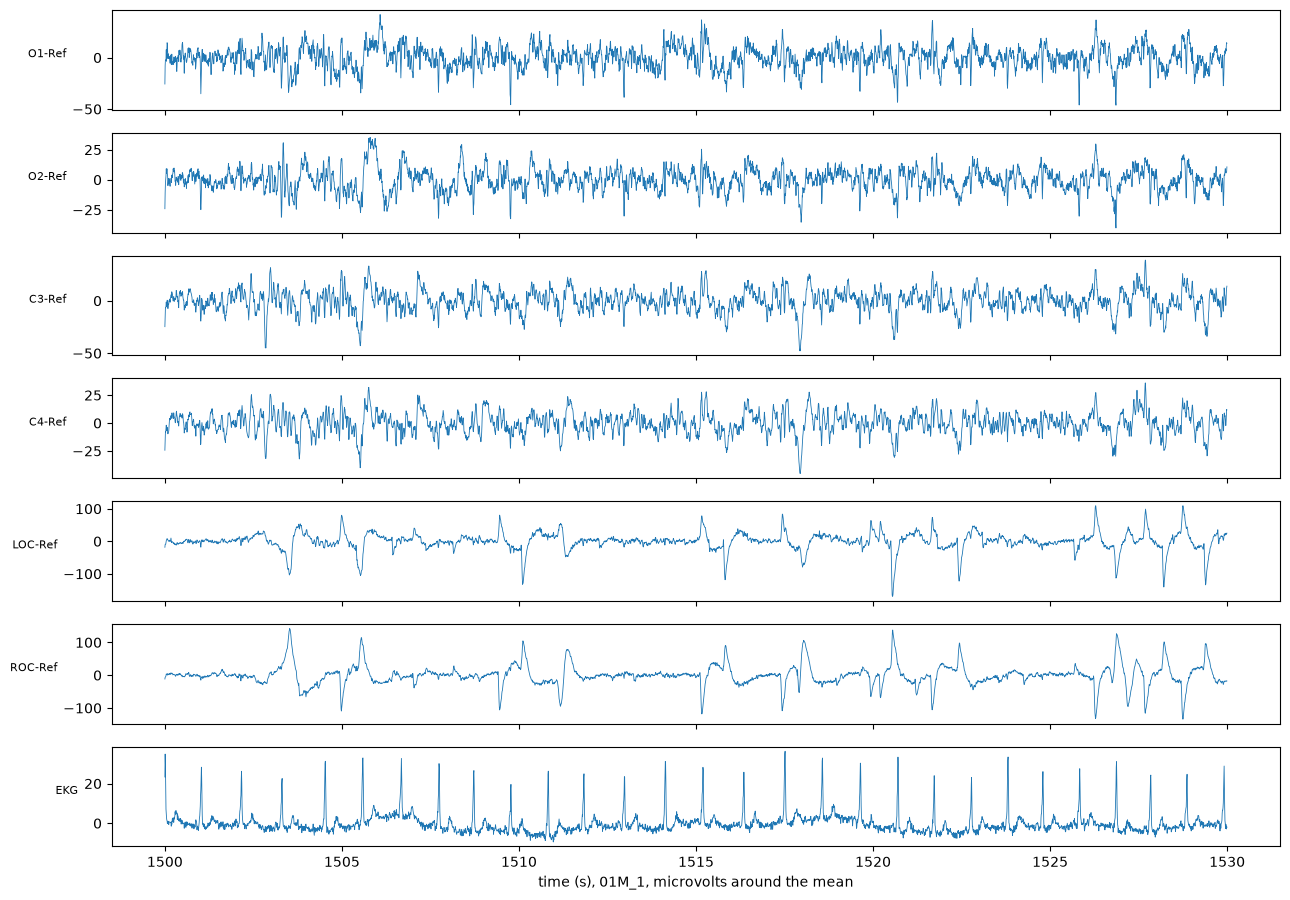

In [6]:
name = DATASET["recordings"][0]
signals = data[name]["signals"]
T0 = 1500                                                    # start of the excerpt (s)
t = np.arange(T0 * FS, (T0 + 30) * FS) / FS
fig, axes = plt.subplots(len(signals), 1, figsize=(13, 1.3 * len(signals)), sharex=True)
for ax, (label, x) in zip(axes, signals.items()):
    ax.plot(t, x[T0 * FS:(T0 + 30) * FS] - np.mean(x[T0 * FS:(T0 + 30) * FS]), lw=0.6); ax.set_ylabel(label, rotation=0, ha="right", fontsize=8)
axes[-1].set_xlabel(f"time (s), {name}, microvolts around the mean")
plt.tight_layout(); plt.show()

## 5. The two eye channels
The electrodes sit just below and above the outer corners of the two eyes. When the eyes move or blink, one goes up while the other goes down, so the channels are **mirror images** (negative correlation in the table above) and their **difference** is the clean "eye signal". Noise that hits both electrodes equally is cancelled.

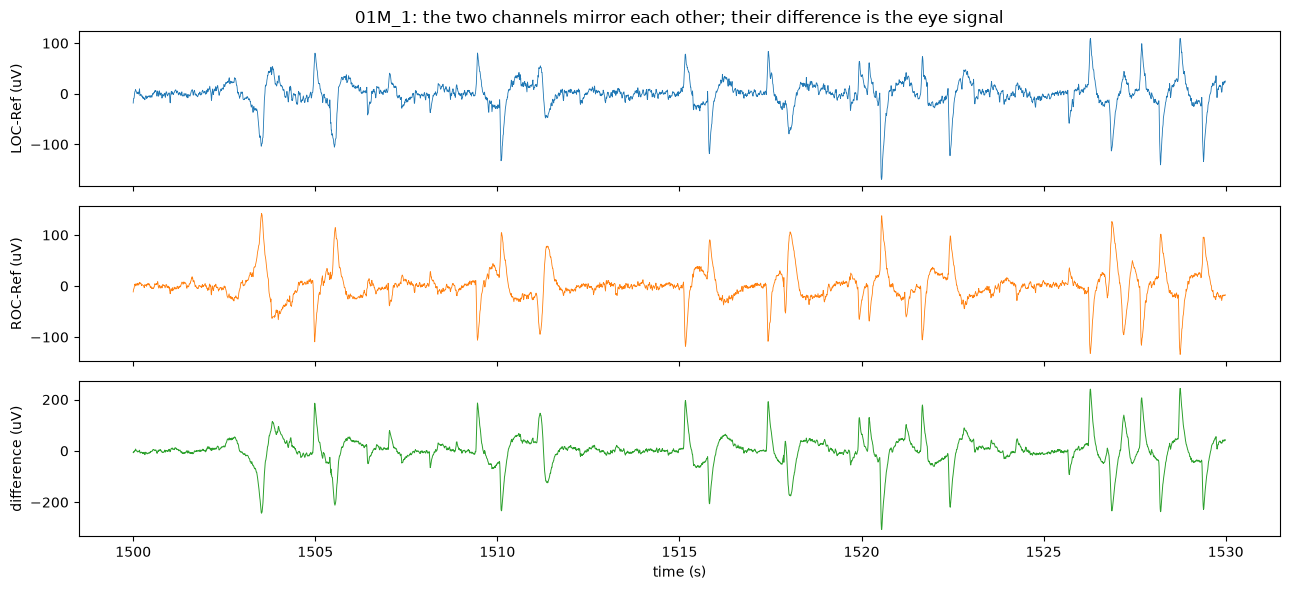

In [7]:
a, b = DATASET["eye_channels"]
sl = slice(T0 * FS, (T0 + 30) * FS)
fig, axes = plt.subplots(3, 1, figsize=(13, 6), sharex=True)
axes[0].plot(t, signals[a][sl] - signals[a][sl].mean(), lw=0.6); axes[0].set_ylabel(a + " (uV)")
axes[1].plot(t, signals[b][sl] - signals[b][sl].mean(), lw=0.6, color="tab:orange"); axes[1].set_ylabel(b + " (uV)")
axes[2].plot(t, eye_signal(data[name])[sl], lw=0.7, color="tab:green"); axes[2].set_ylabel("difference (uV)"); axes[2].set_xlabel("time (s)")
axes[0].set_title(f"{name}: the two channels mirror each other; their difference is the eye signal")
plt.tight_layout(); plt.show()

## 6. Where is the signal's energy? (frequency content)
Power spectrum of the eye signal for every recording. Eye events live below about 10 Hz; the power-line hum shows as a thin spike at the mains frequency (grey line). The detector later keeps only 0.1-20 Hz, so the hum and the fast EEG/muscle noise are removed.

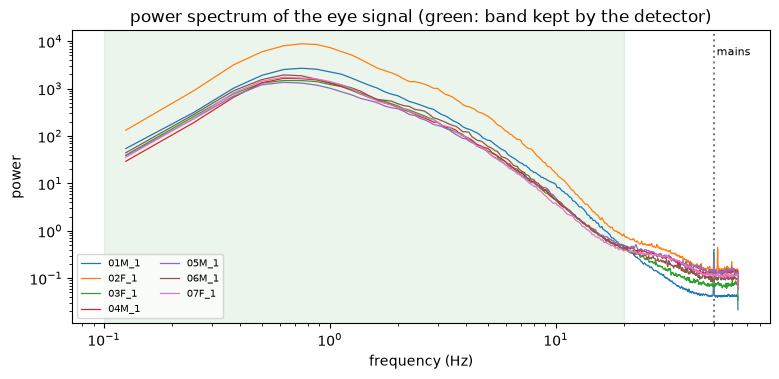

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.8))
for name_, rec in data.items():
    f, pxx = signal.welch(eye_signal(rec) - np.mean(eye_signal(rec)), fs=FS, nperseg=FS * 8)
    ax.loglog(f[1:], pxx[1:], lw=0.9, label=name_)
ax.axvline(DATASET["mains_hz"], color="grey", ls=":"); ax.text(DATASET["mains_hz"] * 1.03, ax.get_ylim()[1] * 0.3, "mains", fontsize=8)
ax.axvspan(0.1, 20, alpha=0.08, color="green"); ax.set_xlabel("frequency (Hz)"); ax.set_ylabel("power"); ax.legend(fontsize=7, ncol=2)
ax.set_title("power spectrum of the eye signal (green: band kept by the detector)")
plt.show()

## 7. How different are the people?
The same eye movement gives a different number of microvolts for every person (skin, electrode contact, placement), and would for a different amplifier gain too. Below: the **typical size** of the signal (robust spread, 0.1-20 Hz) and its **largest swings** (99th percentile) per recording.
If these differ a lot, a fixed limit like "an event is above 200 uV" works for one person and fails for another. The detector therefore measures everything in units of the signal's own noise.

,"typical size, MAD (uV)","largest swings, 99th percentile (uV)"
01M_1,26.2,234.8
02F_1,43.6,427.7
03F_1,21.9,188.5
04M_1,23.0,187.8
05M_1,22.0,170.8
06M_1,18.0,204.5
07F_1,27.7,183.0


typical size differs by a factor 2.4 between the smallest and largest person


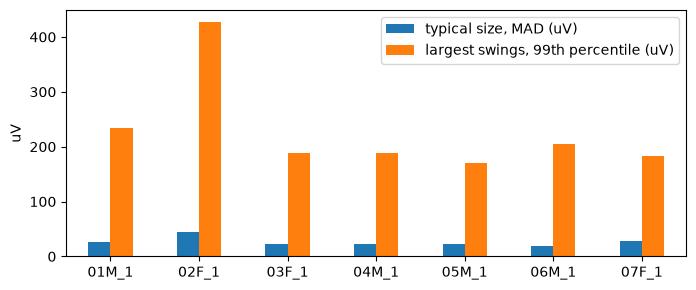

In [9]:
sos = signal.butter(2, [0.1, 20], btype="band", fs=FS, output="sos")
filtered = {n: signal.sosfilt(sos, eye_signal(rec)) for n, rec in data.items()}
scale = pd.DataFrame({n: {"typical size, MAD (uV)": 1.4826 * np.median(np.abs(y - np.median(y))),
                          "largest swings, 99th percentile (uV)": np.percentile(np.abs(y), 99)} for n, y in filtered.items()}).T
display(scale.round(1))
print(f"typical size differs by a factor {scale.iloc[:, 0].max() / scale.iloc[:, 0].min():.1f} between the smallest and largest person")
scale.plot.bar(figsize=(8, 3.2), rot=0); plt.ylabel("uV"); plt.show()

## 8. Slow drift
The median of the raw eye signal per minute through the session. A slow drift (electrode polarisation, sweat, posture) must not be mistaken for eye activity, so the detector removes everything below 0.1 Hz.

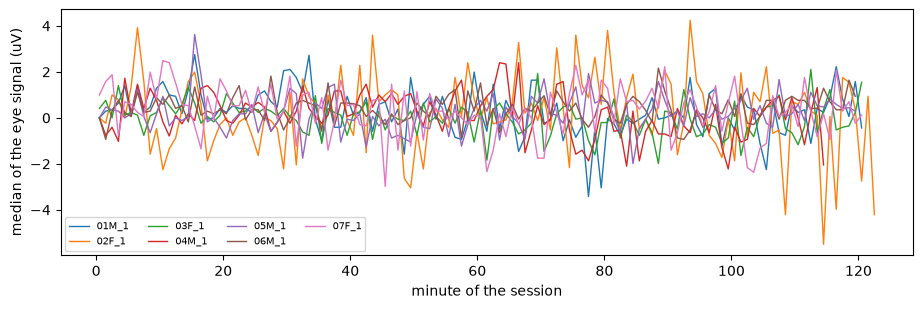

In [10]:
fig, ax = plt.subplots(figsize=(11, 3.2))
for n, rec in data.items():
    x = eye_signal(rec); m = len(x) // (FS * 60)
    ax.plot(np.arange(m) + 0.5, np.median(x[:m * FS * 60].reshape(m, -1), axis=1), lw=1, label=n)
ax.set_xlabel("minute of the session"); ax.set_ylabel("median of the eye signal (uV)"); ax.legend(fontsize=7, ncol=4)
plt.show()

## 9. The marks (button presses)
Each tick is one press of "I feel drowsy". They are the only labels in this dataset, so how they are spread decides what can be learned. People differ in how often they report, and a driver may be drowsy for a while before pressing, or press and then recover, so the labels are **noisy**.

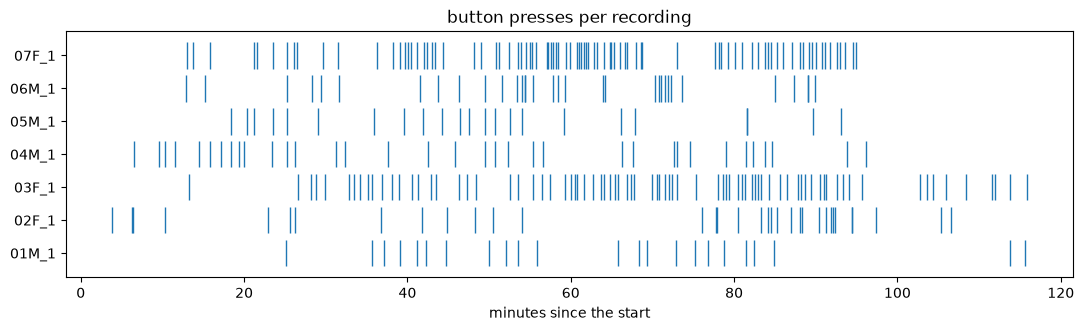

presses in the first hour: 48%, in the second hour: 52%
gap between two presses: median 62 s, shortest 1 s, longest 29 min


In [11]:
fig, ax = plt.subplots(figsize=(13, 3.2))
for i, (n, rec) in enumerate(data.items()):
    ax.vlines(rec["marks"] / 60, i + 0.1, i + 0.9, lw=1)
ax.set_yticks(np.arange(len(data)) + 0.5); ax.set_yticklabels(list(data)); ax.set_xlabel("minutes since the start"); ax.set_title("button presses per recording")
plt.show()
all_marks = np.concatenate([rec["marks"] for rec in data.values()]) / 60
gaps = np.concatenate([np.diff(rec["marks"]) for rec in data.values() if len(rec["marks"]) > 1])
print(f"presses in the first hour: {np.mean(all_marks < 60):.0%}, in the second hour: {np.mean(all_marks >= 60):.0%}")
print(f"gap between two presses: median {np.median(gaps):.0f} s, shortest {gaps.min():.0f} s, longest {gaps.max() / 60:.0f} min")

## 10. Insights
1. **The data is clean.** No missing values, no clipping, and almost no flat seconds (at most 0.07% of the time) in any of the 7 recordings.
2. **The two eye channels mirror each other** (correlation -0.4 to -0.8, section 3), so the difference is the right eye signal. Two recordings (03F_1, 06M_1) are only about -0.4: their electrodes picked up more that is not eye movement, so expect them to be harder.
3. **Eye events are slow and low-frequency**: most power lies below 10 Hz, thousands of times above the 30-60 Hz band. The 50 Hz hum is clear in one recording (01M_1, about 8 times its neighbouring frequencies) but barely visible in the others after the subtraction, so a notch filter is harmless but not critical here.
4. **People differ in scale**: the typical signal size differs by a factor of 2.4 and the largest swings by 2.5 between the smallest and largest recording (02F_1 is the largest). A fixed microvolt limit would suit one person and not another, which is why the detector uses the signal's own noise level.
5. **Drift is small in the eye signal**: the per-minute median moves by only about 5 uV, against a typical signal size of 20-45 uV. It is still removed (high-pass 0.1 Hz) as it would grow with a bad electrode.
6. **Labels are the weak point**: 23 to 88 presses per recording, spread evenly over both hours (48% / 52%), with a median gap of about a minute but gaps from 1 s to 29 min. Subjects 3 and 7 press three to four times as often as subjects 1 and 5. Any drowsiness model trained on these labels inherits that noise.